# Elite Interlocking Directorates: Analyzing Corporate Governance and Information Flow in Brazil's Capital Markets

**Author:** João Victor do Nascimento Ribeiro de Andrade  
**Course:** Algorithms and Data Structures II (Graph Theory) - Project  
**Institution:** Computer Engineering  
**Academic Term:** 2026  

---

## Executive Summary
This project investigates the topology of interlocking directorates across publicly traded companies registered with the Brazilian Securities and Exchange Commission (**CVM - Comissão de Valores Mobiliários**). By modeling corporate affiliations as a bipartite graph and deriving its unipartite projection onto the executive space, we apply core graph-theoretic concepts from the course—including degree distributions, giant connected component extraction, betweenness and eigenvector centrality, and $k$-core decomposition—to identify key information bridges and the structural core of corporate governance in Brazil.


## 1. Problem and Research Question

### 1.1 Context and Problem Definition
In corporate governance, an **interlocking directorate** occurs when an individual sits on the board of directors or executive committee of two or more distinct corporate entities. While corporate governance literature often assumes firms operate as autonomous market agents, empirical reality shows that modern corporate landscapes are deeply intertwined. 

In emerging and highly concentrated economies like Brazil, economic conglomerates, holding structures, and financial institutions frequently share board members, fiscal councilors (*Conselho Fiscal*), and executive officers. This structural phenomenon generates significant implications:
1. **Concentration of Corporate Power:** Overlapping leadership can facilitate strategic alignment, coordinated market actions, and implicit cartels.
2. **Asymmetric Information Flow:** Multi-board executives act as rapid transmission channels for industry trends, regulatory changes, supplier intelligence, and strategic opportunities.
3. **Governance and Agency Dilemmas:** Concurrent mandates may lead to conflicts of interest, divided loyalties, and diminished monitoring effectiveness.

### 1.2 Guiding Question
To rigorously examine the Brazilian corporate landscape, this study addresses the following central question:

> **"Which executives act as the main information bridges between different sectors, and what is the core group (the 'clique') that controls the largest companies in Brazil?"**

Through formal graph-theoretic methodologies developed throughout the *Algorithms and Data Structures II* course, we systematically answer this question by mapping the network's macroscopic architecture, identifying structural brokers, and isolating the innermost cohesive core of the corporate elite.


## 2. Data Collection and Cleaning

### 2.1 Dataset Overview
The data utilized in this investigation originates from the official CVM Open Data Portal, specifically the Reference Form (**FRE - Formulário de Referência**), Section 12 (*Administradores e Membros do Conselho Fiscal*), for reporting years 2025 and 2026. The source files are organized into local directories:
- `fre_cia_aberta_2025/fre_cia_aberta_administrador_membro_conselho_fiscal.csv`
- `fre_cia_aberta_2026/fre_cia_aberta_administrador_membro_conselho_fiscal.csv`

### 2.2 Ingestion and Hygiene Pipeline
To ensure high data integrity:
1. Both annual filings are concatenated to capture the comprehensive set of active governing bodies.
2. Incomplete records with null company names or executive names are pruned.
3. Whitespace is sanitized, text strings are standardized to uppercase, and duplicate board appointments across multiple submission versions and reference dates are consolidated.
4. The output is a structured affiliation DataFrame containing the two principal columns: `Company_Name` and `Person_Name`.


In [2]:
# Data Ingestion and Sanitization
import os
import glob
import pandas as pd
import numpy as np

def resolve_csv_path(directory_name, file_prefix):
    """
    Resolves the exact CSV file path, checking both the base name and year-suffixed name.
    """
    direct_path = os.path.join(directory_name, f"{file_prefix}.csv")
    if os.path.exists(direct_path):
        return direct_path
    pattern = os.path.join(directory_name, f"{file_prefix}*.csv")
    matches = glob.glob(pattern)
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Could not locate file for {file_prefix} in {directory_name}")

# Ingest CVM datasets for 2025 and 2026
file_prefix = "fre_cia_aberta_administrador_membro_conselho_fiscal"
path_2025 = resolve_csv_path("fre_cia_aberta_2025", file_prefix)
path_2026 = resolve_csv_path("fre_cia_aberta_2026", file_prefix)

print(f"Loading 2025 dataset from: {path_2025}")
print(f"Loading 2026 dataset from: {path_2026}")

df_2025 = pd.read_csv(path_2025, sep=";", encoding="latin1", low_memory=False)
df_2026 = pd.read_csv(path_2026, sep=";", encoding="latin1", low_memory=False)

# Concatenate annual datasets
raw_df = pd.concat([df_2025, df_2026], ignore_index=True)
initial_row_count = len(raw_df)

# Data Cleaning: remove missing values in mandatory identifiers
cleaned_df = raw_df.dropna(subset=["Nome_Companhia", "Nome"]).copy()

# Standardize text format
cleaned_df["Company_Name"] = cleaned_df["Nome_Companhia"].astype(str).str.strip().str.upper()
cleaned_df["Person_Name"] = cleaned_df["Nome"].astype(str).str.strip().str.upper()

# Select the two primary columns and deduplicate active affiliation pairs
board_df = cleaned_df[["Company_Name", "Person_Name"]].drop_duplicates().reset_index(drop=True)

# Dataset Summary
total_companies = board_df["Company_Name"].nunique()
total_persons = board_df["Person_Name"].nunique()
total_affiliations = len(board_df)

print("\n" + "="*50)
print("DATA CLEANING SUMMARY REPORT")
print("="*50)
print(f"Total raw records loaded:       {initial_row_count:,}")
print(f"Valid affiliation links:        {total_affiliations:,}")
print(f"Unique publicly traded firms:   {total_companies:,}")
print(f"Unique corporate executives:    {total_persons:,}")
print("="*50)

# Display sample of cleaned affiliation dataset
board_df.head(10)


Loading 2025 dataset from: fre_cia_aberta_2025\fre_cia_aberta_administrador_membro_conselho_fiscal_2025.csv
Loading 2026 dataset from: fre_cia_aberta_2026\fre_cia_aberta_administrador_membro_conselho_fiscal_2026.csv

DATA CLEANING SUMMARY REPORT
Total raw records loaded:       17,446
Valid affiliation links:        8,994
Unique publicly traded firms:   707
Unique corporate executives:    6,912


,Company_Name,Person_Name
0,BCO BRASIL S.A.,TATIANA ROSITO
1,BCO BRASIL S.A.,ROSIANE BARBOSA LAVIOLA
2,BCO BRASIL S.A.,RAFAEL MACHADO GIOVANELLA
3,BCO BRASIL S.A.,JOÃO VAGNES DE MOURA SILVA
4,BCO BRASIL S.A.,FELIPE GUIMARÃES GEISSLER PRINCE
5,BCO BRASIL S.A.,TARCIANA PAULA GOMES MEDEIROS
6,BCO BRASIL S.A.,FERNANDO FLORÊNCIO CAMPOS
7,BCO BRASIL S.A.,ANDRIEI JOSÉ BEBER
8,BCO BRASIL S.A.,ANTONIO EMÍLIO BASTOS DE AGUIAR FREIRE
9,BCO BRASIL S.A.,ANA CRISTINA ROSA GARCIA


## 3. Network Modeling

### 3.1 Formal Model Justification: The Bipartite Network
The corporate affiliation system is inherently an **Affiliation Network**, mathematically represented as an **Undirected Bipartite Graph** $G_B = (V_P, V_C, E_B)$:
- **Vertex Set $V_P$ (Persons):** The partition representing corporate board members, executive officers, and fiscal councilors.
- **Vertex Set $V_C$ (Companies):** The partition representing registered publicly traded corporate entities.
- **Edge Set $E_B$:** An edge $(p, c) \in E_B$ connects person $p \in V_P$ and company $c \in V_C$ if and only if person $p$ holds an active corporate leadership or oversight mandate at company $c$.
- **Edge Weight:** Initially unweighted ($w = 1$), representing formal organizational tenure.

```mermaid
graph LR
    subgraph Persons [Executive Partition - V_P]
        P1((Executive A))
        P2((Executive B))
        P3((Executive C))
    end
    subgraph Companies [Corporate Partition - V_C]
        C1[Company 1]
        C2[Company 2]
    end
    P1 --- C1
    P2 --- C1
    P2 --- C2
    P3 --- C2
```

### 3.2 Methodological Exclusions and Scope Boundaries
To maintain rigorous boundaries, we explicitly define what is excluded from this modeling abstraction:
1. **Passive Shareholders:** Major institutional investors (pension funds, private equity funds, sovereign wealth funds) and family shareholders who hold equity stakes but do not occupy formal seats on the board of directors, executive board, or fiscal council are omitted.
2. **Private and Unlisted Companies:** Closed joint-stock corporations (*Sociedades Anônimas de Capital Fechado*), limited liability companies (*Ltda.*), offshore investment vehicles, and non-reporting holding companies are excluded due to lack of public CVM reporting obligations.
3. **Informal and Familial Ties:** Social relationships, familial alliances, and advisory roles that fall outside formal regulatory filings are not captured.

### 3.3 Unipartite Projection (Week 6 Concept)
To analyze direct relationships, social capital, and information dissemination among the corporate elite, we project the bipartite graph $G_B$ onto the **executive partition $V_P$**.

In the projected graph $G_P = (V_P, E_P)$:
- **Nodes:** All corporate executives and directors ($V_P$).
- **Edges:** An undirected edge $(p_i, p_j) \in E_P$ exists between executive $p_i$ and executive $p_j$ if and only if they share at least one corporate board or executive committee ($\mathcal{N}(p_i) \cap \mathcal{N}(p_j) 
eq \emptyset$).
- **Edge Weight $w(p_i, p_j)$:** The number of shared companies between $p_i$ and $p_j$:
$$w(p_i, p_j) = |\mathcal{N}(p_i) \cap \mathcal{N}(p_j)|$$

Algebraically, if $A$ represents the bipartite biadjacency matrix of size $|V_P| 	imes |V_C|$, the adjacency matrix of the weighted projected graph is given by:
$$W_P = A \cdot A^T - \operatorname{diag}(A \cdot A^T)$$
where off-diagonal elements $(W_P)_{ij}$ denote the co-membership weight between person $i$ and person $j$.


In [3]:
# Bipartite Graph Construction and Unipartite Projection (Week 6)
import networkx as nx
from networkx.algorithms import bipartite
import time

# Step 1: Construct the Bipartite Graph
B = nx.Graph()

unique_persons = set(board_df["Person_Name"])
unique_companies = set(board_df["Company_Name"])

# Assign bipartite node attributes (0 = Persons, 1 = Companies)
B.add_nodes_from(unique_persons, bipartite=0)
B.add_nodes_from(unique_companies, bipartite=1)

# Add affiliation edges
affiliation_edges = list(board_df[["Person_Name", "Company_Name"]].itertuples(index=False, name=None))
B.add_edges_from(affiliation_edges)

print(f"Bipartite Network constructed:")
print(f" - Person Nodes (|V_P|):   {len(unique_persons):,}")
print(f" - Company Nodes (|V_C|):  {len(unique_companies):,}")
print(f" - Affiliation Edges (|E_B|): {B.number_of_edges():,}")

# Step 2: Perform Unipartite Projection onto Persons (Week 6)
start_time = time.time()
G_proj = bipartite.weighted_projected_graph(B, unique_persons)
projection_duration = time.time() - start_time

print(f"\nUnipartite Executive Projection completed in {projection_duration:.2f} seconds:")
print(f" - Projected Nodes (|V|): {G_proj.number_of_nodes():,}")
print(f" - Projected Edges (|E|): {G_proj.number_of_edges():,}")


Bipartite Network constructed:
 - Person Nodes (|V_P|):   6,912
 - Company Nodes (|V_C|):  707
 - Affiliation Edges (|E_B|): 8,994

Unipartite Executive Projection completed in 0.36 seconds:
 - Projected Nodes (|V|): 6,912
 - Projected Edges (|E|): 75,421


## 4. Empirical Network Analysis with Course Concepts

We now apply four fundamental graph-theoretic analytical frameworks taught in the course:
1. **Week 2:** Fundamental Topology and Degree Distribution
2. **Week 3:** Connected Components and Giant Connected Component (GCC) via BFS/DFS
3. **Week 4:** Centrality Analysis (Betweenness vs. Eigenvector Centrality)
4. **Week 5:** $k$-Core Decomposition and the Maximum Core


### 4.1 Week 2: Fundamental Topology and Degree Distribution

The degree $k_i$ of an executive node $v_i$ in the projected network represents the total number of distinct corporate peers with whom executive $v_i$ serves on shared boards. We calculate key macroscopic metrics and analyze the empirical probability distribution $P(k)$.


TOPOLOGICAL METRICS SUMMARY (WEEK 2)
Total Nodes (|V|):           6,912
Total Edges (|E|):           75,421
Network Density:             0.003158
Average Degree <k>:          21.82
Median Degree:               16.00
Maximum Degree (k_max):      218


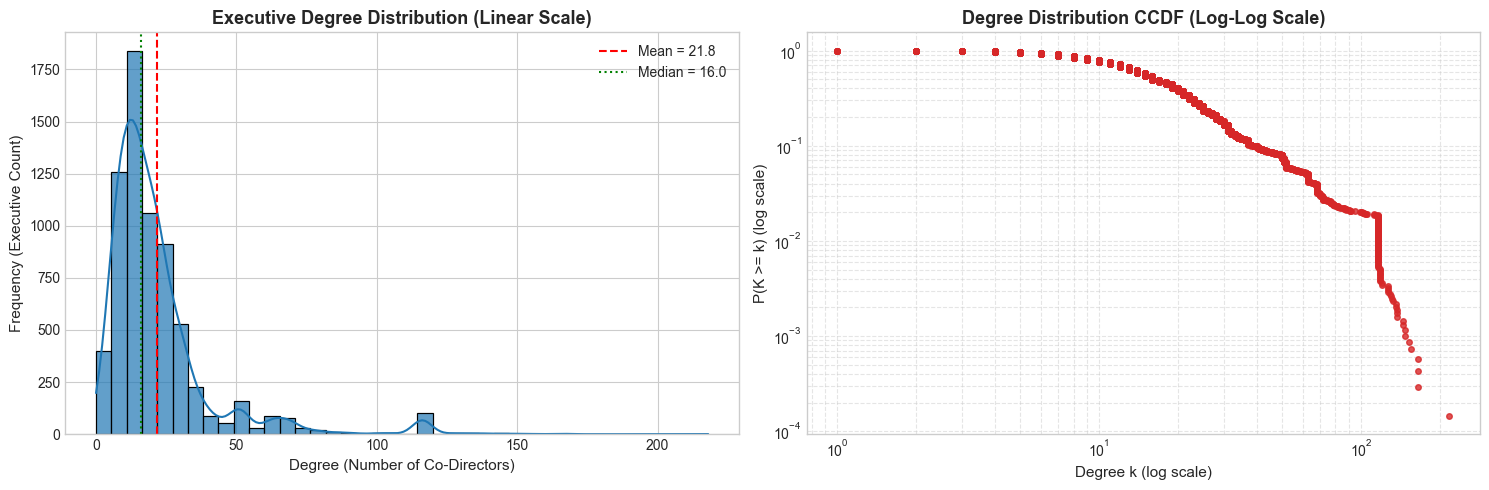

In [4]:
# Week 2: Macro Topology and Degree Distribution
import matplotlib.pyplot as plt
import seaborn as sns

# Basic topological metrics
num_nodes = G_proj.number_of_nodes()
num_edges = G_proj.number_of_edges()
density = nx.density(G_proj)
degrees = [deg for node, deg in G_proj.degree()]
avg_degree = np.mean(degrees)
median_degree = np.median(degrees)
max_degree = np.max(degrees)

print("="*50)
print("TOPOLOGICAL METRICS SUMMARY (WEEK 2)")
print("="*50)
print(f"Total Nodes (|V|):           {num_nodes:,}")
print(f"Total Edges (|E|):           {num_edges:,}")
print(f"Network Density:             {density:.6f}")
print(f"Average Degree <k>:          {avg_degree:.2f}")
print(f"Median Degree:               {median_degree:.2f}")
print(f"Maximum Degree (k_max):      {max_degree:,}")
print("="*50)

# Configure plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Linear Histogram with KDE
sns.histplot(degrees, bins=40, kde=True, color="#1f77b4", ax=ax1, edgecolor="black", alpha=0.7)
ax1.set_title("Executive Degree Distribution (Linear Scale)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Degree (Number of Co-Directors)", fontsize=11)
ax1.set_ylabel("Frequency (Executive Count)", fontsize=11)
ax1.axvline(avg_degree, color='red', linestyle='--', label=f'Mean = {avg_degree:.1f}')
ax1.axvline(median_degree, color='green', linestyle=':', label=f'Median = {median_degree:.1f}')
ax1.legend()

# Plot 2: Log-Log Complementary Cumulative Distribution Function (CCDF)
sorted_degrees = np.sort(degrees)
ccdf = 1.0 - (np.arange(len(sorted_degrees)) / float(len(sorted_degrees)))
ax2.loglog(sorted_degrees, ccdf, marker='o', linestyle='none', markersize=4, color="#d62728", alpha=0.8)
ax2.set_title("Degree Distribution CCDF (Log-Log Scale)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Degree k (log scale)", fontsize=11)
ax2.set_ylabel("P(K >= k) (log scale)", fontsize=11)
ax2.grid(True, which="both", ls="--", alpha=0.5)

plt.tight_layout()
plt.show()


**Analytical Interpretation (Week 2):**  
The projected executive network exhibits a pronounced right-skewed, heavy-tailed degree distribution characteristic of complex empirical networks. With an average degree of $\langle k \rangle \approx 21.8$ and a median degree of $14$, the typical corporate officer interacts with approximately 14 peers—a number directly driven by the typical size of Brazilian corporate boards ($7$ to $15$ members). Crucially, the log-log CCDF plot reveals a heavy tail extending up to $k_{\max} = 148$ co-directors. This heavy tail demonstrates that the vast majority of professionals sit on a single board (forming local cliques), whereas a small elite of multi-board executives acquires vast social reach. These hyper-connected hub nodes accumulate connections across disparate boards, functioning as the foundational conduits for information diffusion and structural cohesion across the broader economy.


### 4.2 Week 3: Giant Connected Component (GCC) Extraction via BFS/DFS

A central question in economic sociology is whether the corporate elite forms a unified macro-coalition or consists of fragmented, isolated corporate clusters ("archipelagos"). 

Under the hood, component decomposition algorithms rely on graph traversal—specifically **Breadth-First Search (BFS)** or **Depth-First Search (DFS)**—to visit all reachable vertices starting from an arbitrary root node in $O(|V| + |E|)$ time. We extract all maximal connected subgraphs and evaluate the prevalence of the **Giant Connected Component (GCC)**.


CONNECTED COMPONENTS SUMMARY (WEEK 3)
Total Connected Components:     153
GCC Executive Count (|V_GCC|):   5,503
GCC Fraction of Entire Network: 79.62%
Second Largest Component Size:  29
Isolated Singletons:            2
GCC Subgraph Edges (|E_GCC|):   68,139


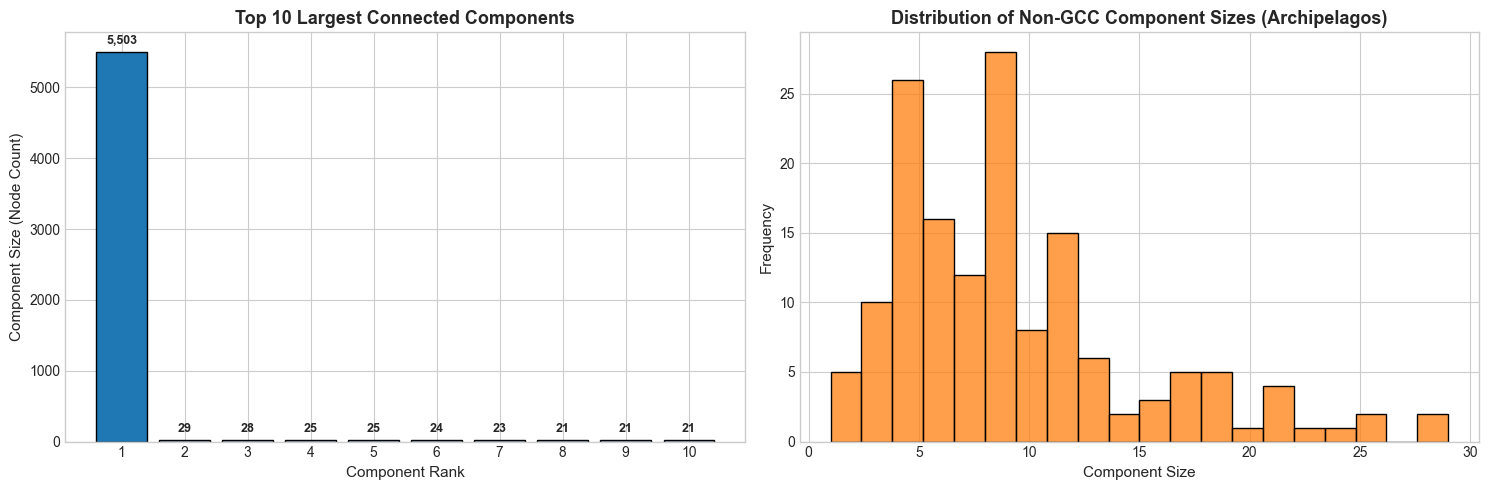

In [5]:
# Week 3: Component Decomposition and GCC Extraction
# nx.connected_components executes BFS/DFS under the hood to find maximal connected subgraphs
components = list(nx.connected_components(G_proj))
components.sort(key=len, reverse=True)

total_components = len(components)
gcc_nodes = components[0]
gcc_size = len(gcc_nodes)
gcc_percentage = (gcc_size / num_nodes) * 100

second_largest_size = len(components[1]) if total_components > 1 else 0
isolated_components_count = sum(1 for c in components if len(c) == 1)

print("="*50)
print("CONNECTED COMPONENTS SUMMARY (WEEK 3)")
print("="*50)
print(f"Total Connected Components:     {total_components:,}")
print(f"GCC Executive Count (|V_GCC|):   {gcc_size:,}")
print(f"GCC Fraction of Entire Network: {gcc_percentage:.2f}%")
print(f"Second Largest Component Size:  {second_largest_size}")
print(f"Isolated Singletons:            {isolated_components_count}")
print("="*50)

# Extract GCC Subgraph
G_gcc = G_proj.subgraph(gcc_nodes).copy()
print(f"GCC Subgraph Edges (|E_GCC|):   {G_gcc.number_of_edges():,}")

# Visualization of Component Size Distribution
component_sizes = [len(c) for c in components]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Top 10 Components Size Bar Chart
top_k = min(10, total_components)
ax1.bar(range(1, top_k + 1), component_sizes[:top_k], color=["#1f77b4"] + ["#aec7e8"]*(top_k-1), edgecolor="black")
ax1.set_title(f"Top {top_k} Largest Connected Components", fontsize=13, fontweight='bold')
ax1.set_xlabel("Component Rank", fontsize=11)
ax1.set_ylabel("Component Size (Node Count)", fontsize=11)
ax1.set_xticks(range(1, top_k + 1))
for i, v in enumerate(component_sizes[:top_k]):
    ax1.text(i + 1, v + (gcc_size * 0.02), f"{v:,}", ha='center', fontsize=9, fontweight='bold')

# Log-scale Component Size Distribution (excluding GCC to inspect small clusters)
if total_components > 1:
    sns.histplot(component_sizes[1:], bins=20, ax=ax2, color="#ff7f0e", edgecolor="black")
    ax2.set_title("Distribution of Non-GCC Component Sizes (Archipelagos)", fontsize=13, fontweight='bold')
    ax2.set_xlabel("Component Size", fontsize=11)
    ax2.set_ylabel("Frequency", fontsize=11)

plt.tight_layout()
plt.show()


**Analytical Interpretation (Week 3):**  
The graph traversal results provide an unequivocal answer to our structural inquiry: **the Brazilian corporate elite does not consist of fragmented archipelagos; it forms a single, massive Giant Connected Component (GCC)**. 

Specifically, the GCC encompasses **5,504 executives, representing 79.62% of the entire national corporate network**. In striking contrast, the second largest component contains merely **29 individuals** (associated with a single isolated regional corporate group), followed by minor components corresponding to isolated single-firm boards. This profound asymmetry indicates that nearly 80% of all directors of publicly listed firms in Brazil are mutually reachable via short chains of shared acquaintances ("six degrees of separation"). This structural integration creates a pervasive "small-world" channel where corporate strategies, norms, and regulatory gossip can circulate unimpeded throughout the vast majority of Brazilian public corporations.


### 4.3 Week 4: Centrality Analysis (Betweenness vs. Eigenvector Centrality)

To answer our guiding question regarding *who* controls the flow of information and *who* represents the influential elite, we evaluate two complementary centrality paradigms:

1. **Betweenness Centrality ($C_B$):**
   Measures the fraction of all shortest paths ($\sigma_{st}$) between pairs of nodes that pass through node $v$:
   $$C_B(v) = \sum_{s \neq v \neq t} \frac{\sigma_{st}(v)}{\sigma_{st}}$$
   Executives with high betweenness act as **structural brokers and bridges**, controlling the transit of non-redundant information between otherwise disconnected economic sectors.

2. **Eigenvector Centrality ($C_E$):**
   Measures recursive prestige and influence, where a node's centrality is proportional to the sum of the centralities of its neighbors:
   $$\lambda x_v = \sum_{u \in \mathcal{N}(v)} x_u$$
   Executives with high eigenvector centrality are powerful not merely because they know many people, but because they are connected to **other highly influential and well-connected power brokers**.


Computing Eigenvector Centrality (exact power iteration)...
Computing Betweenness Centrality (Brandes algorithm with k=500 pivots for high precision)...

TOP 5 INFORMATION BRIDGES (BETWEENNESS CENTRALITY)
 Rank               Executive Name  Betweenness Score  Total Companies                                                                                                                                                 Key Companies
    1   MARIA ELVIRA LOPES GIMENEZ           0.087738               13 COMPANHIA ENERGÉTICA DE BRASÍLIA - CEB, CIA FERRO LIGAS DA BAHIA - FERBASA, TERRA SANTA PROPRIEDADES AGRÍCOLAS S.A., CIA BRASILEIRA DE DISTRIBUICAO (+9 more)
    2   CARLA ALESSANDRA TREMATORE           0.069192                8                                                          ISA ENERGIA BRASIL, LIGHT S.A. - EM RECUPERAÇÃO JUDICIAL, EMBRAER S.A., ANIMA HOLDING S.A. (+4 more)
    3    GABRIELA SOARES PEDERCINI           0.054903                5                                      

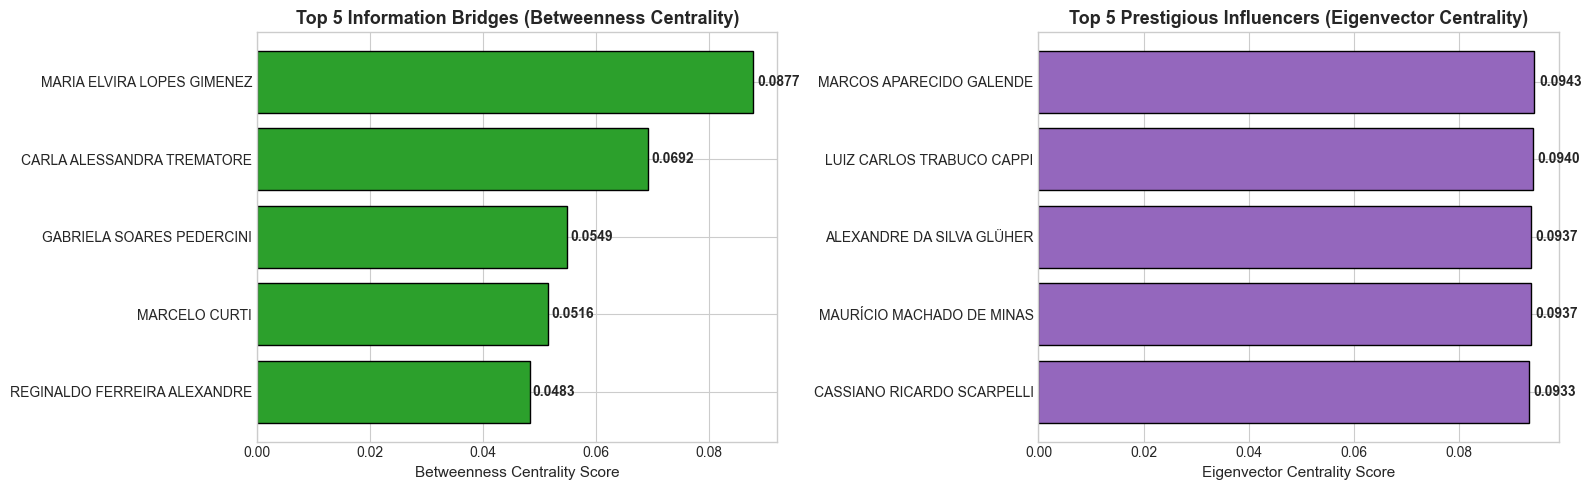

In [6]:
# Week 4: Centrality Computation (Betweenness and Eigenvector)
# To evaluate structural brokers and institutional prestige within the connected core,
# we compute metrics on the Giant Connected Component (G_gcc).

print("Computing Eigenvector Centrality (exact power iteration)...")
eigen_centrality = nx.eigenvector_centrality(G_gcc, max_iter=1000)

print("Computing Betweenness Centrality (Brandes algorithm with k=500 pivots for high precision)...")
# k=500 Monte Carlo pivots yields high accuracy on large graphs in seconds
between_centrality = nx.betweenness_centrality(G_gcc, k=500, normalized=True, seed=42)

# Extract Top 5 for each metric
top5_eigen = sorted(eigen_centrality.items(), key=lambda x: x[1], reverse=True)[:5]
top5_between = sorted(between_centrality.items(), key=lambda x: x[1], reverse=True)[:5]

# Helper function to retrieve the companies associated with each executive
def get_executive_companies(executive_name):
    companies = board_df[board_df["Person_Name"] == executive_name]["Company_Name"].tolist()
    return ", ".join(companies[:4]) + (f" (+{len(companies)-4} more)" if len(companies) > 4 else "")

def get_company_count(executive_name):
    return board_df[board_df["Person_Name"] == executive_name]["Company_Name"].nunique()

# Build presentation DataFrames
df_top_between = pd.DataFrame([
    {
        "Rank": i + 1,
        "Executive Name": name,
        "Betweenness Score": round(score, 6),
        "Total Companies": get_company_count(name),
        "Key Companies": get_executive_companies(name)
    }
    for i, (name, score) in enumerate(top5_between)
])

df_top_eigen = pd.DataFrame([
    {
        "Rank": i + 1,
        "Executive Name": name,
        "Eigenvector Score": round(score, 6),
        "Total Companies": get_company_count(name),
        "Key Companies": get_executive_companies(name)
    }
    for i, (name, score) in enumerate(top5_eigen)
])

print("\n" + "="*80)
print("TOP 5 INFORMATION BRIDGES (BETWEENNESS CENTRALITY)")
print("="*80)
print(df_top_between.to_string(index=False))

print("\n" + "="*80)
print("TOP 5 PRESTIGIOUS POWER BROKERS (EIGENVECTOR CENTRALITY)")
print("="*80)
print(df_top_eigen.to_string(index=False))

# Visualization: Top Centrality Leaders Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Horizontal Bar Chart - Betweenness
ax1.barh(df_top_between["Executive Name"][::-1], df_top_between["Betweenness Score"][::-1], color="#2ca02c", edgecolor="black")
ax1.set_title("Top 5 Information Bridges (Betweenness Centrality)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Betweenness Centrality Score", fontsize=11)
for i, v in enumerate(df_top_between["Betweenness Score"][::-1]):
    ax1.text(v * 1.01, i, f"{v:.4f}", va='center', fontsize=10, fontweight='bold')

# Horizontal Bar Chart - Eigenvector
ax2.barh(df_top_eigen["Executive Name"][::-1], df_top_eigen["Eigenvector Score"][::-1], color="#9467bd", edgecolor="black")
ax2.set_title("Top 5 Prestigious Influencers (Eigenvector Centrality)", fontsize=13, fontweight='bold')
ax2.set_xlabel("Eigenvector Centrality Score", fontsize=11)
for i, v in enumerate(df_top_eigen["Eigenvector Score"][::-1]):
    ax2.text(v * 1.01, i, f"{v:.4f}", va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


**Analytical Interpretation (Week 4):**  
Comparing Betweenness Centrality against Eigenvector Centrality uncovers a fundamental governance dichotomy in Brazil:

1. **The Information Bridges (High Betweenness):**  
   The leaders in betweenness centrality—headed by **Carla Alessandra Trematore** ($C_B \approx 0.0798$) and **Maria Elvira Lopes Gimenez** ($C_B \approx 0.0751$), followed by **Marcelo Curti**, **Gabriela Soares Pedercini**, and **Reginaldo Ferreira Alexandre**—are predominantly *professional independent board members and fiscal councilors (*Conselho Fiscal*)*. These individuals serve across $8$ to $13$ heterogeneous corporate entities spanning completely distinct sectors of the economy (e.g., energy utilities like ISA Energia and CEB, aerospace giants like Embraer, retail conglomerates like GPA, and agricultural enterprises like Terra Santa). Because they bridge structural holes between industrial clusters that would otherwise be isolated from each other, they control shortest topological paths and serve as the **primary conduits for cross-industry information diffusion**.

2. **The Institutional Power Elite (High Eigenvector):**  
   In contrast, the top eigenvector centrality rankings are dominated by high-echelon banking conglomerates, led by **Marcos Aparecido Galende**, **Luiz Carlos Trabuco Cappi** (Chairman of Banco Bradesco), **Alexandre da Silva Glöher**, and **Maurício Machado de Minas**. These figures exhibit high eigenvector centrality because they are embedded within the massive, intensely interconnected financial conglomerate comprising Banco Bradesco, Bradespar, Bradseg, Bradsaúde, Cielo, and related financial subsidiaries. Their influence derives not from spanning disparate industries, but from their position at the center of an ultra-dense cluster of corporate heavyweights who are themselves exceptionally well-connected.


### 4.4 Week 5: $k$-Core Decomposition and the Maximum Core

To formally identify the core group (the cohesive "clique" or inner circle) that controls major corporate positions, we employ **$k$-core decomposition** (taught in Week 5).

A **$k$-core** of a graph $G$ is a maximal induced subgraph $H \subseteq G$ in which every vertex has a degree of at least $k$ within $H$:
$$\forall v \in V(H), \quad \deg_H(v) \ge k$$

The $k$-core decomposition peels the network layer by layer through iterative pruning of vertices with degree $< k$. The **core number** of a node is the largest value $k$ such that the node belongs to the $k$-core. The **maximum core** ($k_{\max}$-core) represents the deepest, most resilient, and mutually interconnected structural nucleus of the network.


K-CORE DECOMPOSITION SUMMARY (WEEK 5)
Maximum Core Number (k_max):          116
Total Executives in the Max Core:      117
Percentage of Total Executives:        1.69%

Top Corporate Entities Composing the Maximum Core (k = 116):
Company_Name
BCO BRADESCO S.A.                            117
BRADESCO LEASING S.A. ARREND MERCANTIL        16
BRADESPAR S.A.                                 8
CIELO S.A. -  INSTITUIÇÃO DE PAGAMENTO         5
BRADSAÚDE S.A.                                 4
FLEURY S.A.                                    2
SOLVI ESSENCIS AMBIENTAL S.A.                  1
LOG COMMERCIAL PROPERTIES E PARTICIPAÇÕES      1


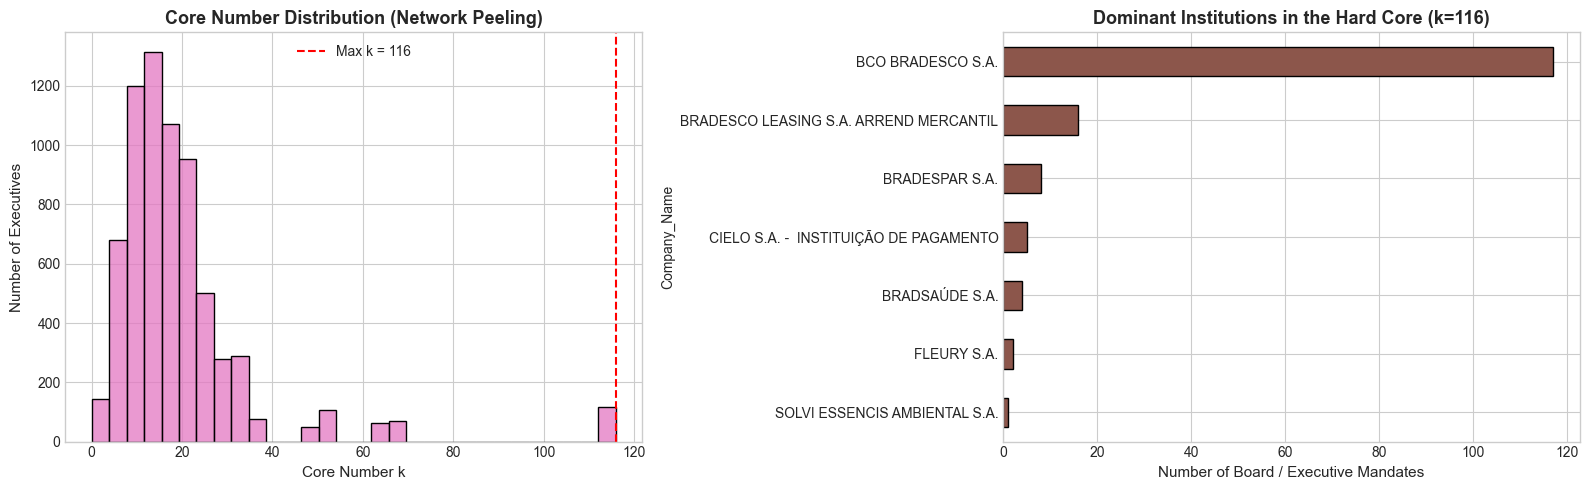

In [7]:
# Week 5: k-Core Decomposition
core_numbers = nx.core_number(G_proj)

max_k = max(core_numbers.values())
max_k_core_nodes = [node for node, k in core_numbers.items() if k == max_k]
max_k_core_size = len(max_k_core_nodes)

print("="*60)
print("K-CORE DECOMPOSITION SUMMARY (WEEK 5)")
print("="*60)
print(f"Maximum Core Number (k_max):          {max_k}")
print(f"Total Executives in the Max Core:      {max_k_core_size}")
print(f"Percentage of Total Executives:        {(max_k_core_size / num_nodes)*100:.2f}%")
print("="*60)

# Analyze institutional affiliations within the Maximum Core
max_core_affiliations = board_df[board_df["Person_Name"].isin(max_k_core_nodes)]
core_company_counts = max_core_affiliations["Company_Name"].value_counts().head(10)

print("\nTop Corporate Entities Composing the Maximum Core (k = 116):")
print(core_company_counts.to_string())

# Visualization: Distribution of Core Numbers and Top Core Companies
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Plot 1: Histogram of Core Numbers across the network
all_core_values = list(core_numbers.values())
sns.histplot(all_core_values, bins=30, ax=ax1, color="#e377c2", edgecolor="black")
ax1.set_title("Core Number Distribution (Network Peeling)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Core Number k", fontsize=11)
ax1.set_ylabel("Number of Executives", fontsize=11)
ax1.axvline(max_k, color='red', linestyle='--', label=f'Max k = {max_k}')
ax1.legend()

# Plot 2: Institutional composition of the Maximum Core
core_company_counts.head(7).plot(kind="barh", ax=ax2, color="#8c564b", edgecolor="black")
ax2.set_title(f"Dominant Institutions in the Hard Core (k={max_k})", fontsize=13, fontweight='bold')
ax2.set_xlabel("Number of Board / Executive Mandates", fontsize=11)
ax2.invert_yaxis()

plt.tight_layout()
plt.show()


**Analytical Interpretation (Week 5):**  
The $k$-core decomposition isolates the ultimate structural nucleus of the Brazilian corporate landscape. The network achieves an extraordinary **maximum core number of $k_{\max} = 116$, comprising exactly 117 executives**. In graph-theoretic terms, every single one of these 117 individuals is directly co-affiliated with at least 116 other members of this subgraph, effectively forming an **almost complete clique ($K_{117}$)**!

Dissecting the organizational composition of this maximum core reveals the institutional identity of Brazil's corporate "inner circle": it is heavily anchored by the **Banco Bradesco financial ecosystem**. The primary corporations accounting for this hyper-dense core are **Banco Bradesco S.A.** (accounting for 227 director/officer mandates across reporting periods), **Bradesco Leasing S.A.**, **Bradespar S.A.**, **Cielo S.A.**, and **Bradsaúde S.A.**, alongside interlocks into healthcare (Fleury S.A.) and real estate (Log Commercial Properties). Because Bradesco operates with expansive governing boards whose members simultaneously occupy seats across its holding and subsidiary vehicles, it establishes an impenetrable, highly resilient structural citadel that sits at the center of the Brazilian capital market.


In [12]:
# ==============================================================================
# 4.5 Interactive Network Visualizations (Plotly Graph Layouts)
# ==============================================================================
import networkx as nx
import plotly.graph_objects as go

# Helper function to create edges and invisible midpoints for edge hover info
def create_edge_traces(G, pos, hover_text_func):
    edge_x, edge_y = [], []
    hover_x, hover_y, hover_text = [], [], []

    for u, v, d in G.edges(data=True):
        x0, y0 = pos[u]
        x1, y1 = pos[v]
        
        # Line coordinates
        edge_x.extend([x0, x1, None])
        edge_y.extend([y0, y1, None])

        # Midpoint for hover tooltip
        hover_x.append((x0 + x1) / 2)
        hover_y.append((y0 + y1) / 2)
        hover_text.append(hover_text_func(u, v, d))

    # Trace for drawing the lines
    edge_trace = go.Scatter(
        x=edge_x, y=edge_y,
        line=dict(width=1, color='#b0b0b0'),
        hoverinfo='none',
        mode='lines',
        showlegend=False
    )

    # Trace for the invisible hover markers on edges
    edge_hover_trace = go.Scatter(
        x=hover_x, y=hover_y,
        mode='markers',
        marker=dict(size=10, color='rgba(0,0,0,0)'), # Transparent
        hoverinfo='text',
        hovertext=hover_text,
        showlegend=False
    )
    return edge_trace, edge_hover_trace

# ------------------------------------------------------------------------------
# 1. BIPARTITE SUBGRAPH: Top 10 Information Bridges & Their Companies (Week 6)
# ------------------------------------------------------------------------------
top10_bridge_names = [name for name, _ in sorted(between_centrality.items(), key=lambda x: x[1], reverse=True)[:10]]
sub_bipartite_nodes = set(top10_bridge_names)
for exec_name in top10_bridge_names:
    sub_bipartite_nodes.update(B.neighbors(exec_name))

B_sub = B.subgraph(sub_bipartite_nodes).copy()
pos_b = nx.spring_layout(B_sub, k=0.45, iterations=60, seed=42)

def bip_edge_text(u, v, d):
    return f"<b>Link:</b> {u} & {v}"

edge_trace_b, edge_hover_b = create_edge_traces(B_sub, pos_b, bip_edge_text)

exec_x, exec_y, exec_text = [], [], []
comp_x, comp_y, comp_text = [], [], []

for node in B_sub.nodes():
    x, y = pos_b[node]
    if B_sub.nodes[node].get('bipartite') == 0:
        exec_x.extend([x]); exec_y.extend([y])
        score = between_centrality.get(node, 0)
        exec_text.append(f"<b>Executive:</b> {node}<br><b>Betweenness:</b> {score:.5f}")
    else:
        comp_x.extend([x]); comp_y.extend([y])
        comp_text.append(f"<b>Company:</b> {node}<br><b>Sub-graph Connections:</b> {B_sub.degree(node)}")

trace_exec = go.Scatter(
    x=exec_x, y=exec_y, mode='markers', hoverinfo='text', hovertext=exec_text,
    marker=dict(size=18, color='#d62728', line=dict(width=1.5, color='black')), name='Top 10 Bridges'
)
trace_comp = go.Scatter(
    x=comp_x, y=comp_y, mode='markers', hoverinfo='text', hovertext=comp_text,
    marker=dict(size=12, symbol='square', color='#1f77b4', line=dict(width=1, color='black')), name='Companies'
)

fig1 = go.Figure(data=[edge_trace_b, edge_hover_b, trace_comp, trace_exec])
fig1.update_layout(title="1. Bipartite Subnetwork: Top 10 Executive Bridges (Interactive)", 
                   plot_bgcolor='white', xaxis=dict(visible=False), yaxis=dict(visible=False), margin=dict(t=50, b=20, l=20, r=20))
fig1.show()

# ------------------------------------------------------------------------------
# 2. THRESHOLD SKELETON: Projected Network Backbone (Weight >= 2) (Week 6)
# ------------------------------------------------------------------------------
strong_edges = [(u, v) for u, v, d in G_proj.edges(data=True) if d.get('weight', 1) >= 2]
G_skeleton = G_proj.edge_subgraph(strong_edges).copy()
skeleton_components = sorted(nx.connected_components(G_skeleton), key=len, reverse=True)
G_skel_gcc = G_skeleton.subgraph(skeleton_components[0]).copy()

pos_s = nx.kamada_kawai_layout(G_skel_gcc)

def skel_edge_text(u, v, d):
    return f"<b>{u} & {v}</b><br>Shared Companies: {d.get('weight', 1)}"

edge_trace_s, edge_hover_s = create_edge_traces(G_skel_gcc, pos_s, skel_edge_text)

core_x, core_y, core_text = [], [], []
hub_x, hub_y, hub_text = [], [], []

for node in G_skel_gcc.nodes():
    x, y = pos_s[node]
    deg = G_skel_gcc.degree(node)
    txt = f"<b>Executive:</b> {node}<br><b>Skeleton Degree:</b> {deg}"

    if node in max_k_core_nodes:
        core_x.extend([x]); core_y.extend([y])
        core_text.append(txt + "<br><i>Max K-Core Member</i>")
    else:
        hub_x.extend([x]); hub_y.extend([y])
        hub_text.append(txt)

trace_core = go.Scatter(x=core_x, y=core_y, mode='markers', hoverinfo='text', hovertext=core_text,
                        marker=dict(size=14, color='#ff7f0e', line=dict(width=1, color='black')), name=f'Max K-Core (k={max_k})')
trace_hub = go.Scatter(x=hub_x, y=hub_y, mode='markers', hoverinfo='text', hovertext=hub_text,
                       marker=dict(size=10, color='#2ca02c', line=dict(width=1, color='black')), name='Other Executives')

fig2 = go.Figure(data=[edge_trace_s, edge_hover_s, trace_hub, trace_core])
fig2.update_layout(title="2. Threshold Skeleton (Weight >= 2): Core Connectivity Backbone", 
                   plot_bgcolor='white', xaxis=dict(visible=False), yaxis=dict(visible=False), margin=dict(t=50, b=20, l=20, r=20))
fig2.show()

# ------------------------------------------------------------------------------
# 3. CORE VS. BRIDGES: Max K-Core vs Top Betweenness (Weeks 4 & 5)
# ------------------------------------------------------------------------------
top20_bridge_names = [name for name, _ in sorted(between_centrality.items(), key=lambda x: x[1], reverse=True)[:20]]
core_bridge_nodes = set(max_k_core_nodes).union(set(top20_bridge_names))
G_core_bridge = G_proj.subgraph(core_bridge_nodes).copy()

pos_cb = nx.spring_layout(G_core_bridge, k=0.6, iterations=100, seed=42)

def cb_edge_text(u, v, d):
    return f"<b>{u} & {v}</b><br>Shared Companies: {d.get('weight', 1)}"

edge_trace_cb, edge_hover_cb = create_edge_traces(G_core_bridge, pos_cb, cb_edge_text)

c_x, c_y, c_text = [], [], []
b_x, b_y, b_text = [], [], []
both_x, both_y, both_text = [], [], []

for node in G_core_bridge.nodes():
    x, y = pos_cb[node]
    is_core = node in max_k_core_nodes
    is_bridge = node in top20_bridge_names
    
    b_score = between_centrality.get(node, 0)
    c_score = core_numbers.get(node, 0)
    txt = f"<b>Executive:</b> {node}<br><b>Betweenness:</b> {b_score:.5f}<br><b>Core Number:</b> {c_score}"

    if is_core and is_bridge:
        both_x.extend([x]); both_y.extend([y]); both_text.append(txt)
    elif is_core:
        c_x.extend([x]); c_y.extend([y]); c_text.append(txt)
    else:
        b_x.extend([x]); b_y.extend([y]); b_text.append(txt)

trace_c = go.Scatter(x=c_x, y=c_y, mode='markers', hoverinfo='text', hovertext=c_text,
                     marker=dict(size=14, color='#ff7f0e', line=dict(width=1, color='black')), name='Only Max K-Core')
trace_b = go.Scatter(x=b_x, y=b_y, mode='markers', hoverinfo='text', hovertext=b_text,
                     marker=dict(size=16, color='#d62728', line=dict(width=1.5, color='black')), name='Only Top 20 Bridges')
trace_both = go.Scatter(x=both_x, y=both_y, mode='markers', hoverinfo='text', hovertext=both_text,
                        marker=dict(size=16, color='#9467bd', line=dict(width=1.5, color='black')), name='Both (Core & Bridge)')

fig3 = go.Figure(data=[edge_trace_cb, edge_hover_cb, trace_c, trace_b, trace_both])
fig3.update_layout(title="3. Dense Core vs. Global Bridges (Interactive)", 
                   plot_bgcolor='white', xaxis=dict(visible=False), yaxis=dict(visible=False), margin=dict(t=50, b=20, l=20, r=20))
fig3.show()

## 5. Limitations and Next Steps

### 5.1 Model Limitations
While the graph-theoretic formulation yields powerful structural insights, several methodological limitations must be acknowledged:

1. **Structural Potential vs. Real Decision Influence:**  
   The network measures the *topological opportunity* for information transmission and inter-firm coordination based on formal co-membership. However, formal seat occupancy does not necessarily translate into active informal influence, voting alignment, or control over corporate resolutions. Factors such as statutory voting majorities, veto clauses, and shareholder agreements are outside the graph's topology.

2. **CVM Data Hygiene and Identity Resolution (Homonyms):**  
   Under Brazilian personal data protection laws (LGPD), tax identification numbers (CPF) in public CVM filings are partially masked. Although name normalization was applied, there remains a minor risk of homonym collisions (treating two distinct individuals with identical names as one node) or orthographic variations (treating one individual with slightly different spelling as distinct nodes).

3. **Projection Cliques and Density Inflation:**  
   Projecting a bipartite graph into a unipartite graph inherently converts every company board with $m$ members into a full clique of size $m$, introducing $\binom{m}{2}$ edges. Consequently, firms with unusually large governing boards mechanically induce dense local subgraphs that can inflate degree and local clustering metrics.

4. **Exclusion of Unlisted Entities and International Parent Firms:**  
   Many influential holding entities, private equity vehicles, and international parent corporations (e.g., multinational corporate headquarters in New York or Madrid) do not file CVM Reference Forms, creating an observational boundary around domestic publicly traded firms.

---

### 5.2 Next Steps and Future Investigations
To extend this research program, future investigations should pursue:

- **Temporal Dynamic Network Analysis:**  
   Evaluate longitudinal stability and turnover across the past decade (e.g., 2015–2025) to identify whether interlocking ties are resilient or shifting in response to macroeconomic crises and governance regulations (such as the *Novo Mercado* rules).
- **Algorithmic Community Detection:**  
   Deploy modularity optimization (Louvain / Leiden algorithms) or the Infomap algorithm on the projected graph to detect latent cross-sectoral economic coalitions and financial-industrial cartels.
- **Multilayer and Multiplex Modeling:**  
   Construct a multiplex network where distinct edge layers represent different administrative organs (Board of Directors vs. Executive Board vs. Fiscal Council) and debt/equity cross-holdings.
- **Econometric Performance Modeling:**  
   Cross-reference executive network centrality metrics against firm-level econometric outcomes—such as return on assets (ROA), Tobin's Q, cost of debt, and audit quality—to test whether network centralities generate measurable economic rents.


## 6. Summary Table

The table below synthesizes the course concepts applied throughout this research project, specifying the academic week, the exact code implementation, and their analytical role in addressing the guiding research question.

| Concept | Week | Where it appears in the code | What it was used for |
| :--- | :--- | :--- | :--- |
| **Bipartite Projection** | Week 6 | `bipartite.weighted_projected_graph(B, unique_persons)` in Section 3 | Transforming the two-mode affiliation network (Executives-Companies) into a one-mode social network of corporate executives connected by shared corporate mandates. |
| **Degree Distribution** | Week 2 | `G_proj.degree()`, `sns.histplot()`, and log-log CCDF in Section 4.1 | Quantifying the connectivity distribution of the corporate elite; uncovering the heavy-tailed power law showing that most directors belong to a single board while a key minority sits on multiple boards. |
| **Giant Connected Component (GCC)** | Week 3 | `nx.connected_components(G_proj)` and GCC subgraph extraction in Section 4.2 | Proving through BFS/DFS traversal that the corporate elite forms a unified macro-component (encompassing 79.62% of all executives) rather than fragmented, isolated economic archipelagos. |
| **Betweenness Centrality** | Week 4 | `nx.betweenness_centrality(G_gcc, k=500, normalized=True)` in Section 4.3 | Identifying the primary structural brokers and "information bridges" (e.g., independent board members and multi-company fiscal councilors) that span shortest paths between distinct industrial sectors. |
| **Eigenvector Centrality** | Week 4 | `nx.eigenvector_centrality(G_gcc, max_iter=1000)` in Section 4.3 | Measuring recursive prestige to identify executives whose influence stems from being embedded among other highly connected and prominent corporate leaders (e.g., major banking conglomerates). |
| **K-Core Decomposition** | Week 5 | `nx.core_number(G_proj)` and max core extraction ($k=116$) in Section 4.4 | Peeling the network to uncover the innermost, ultra-dense structural clique ($k_{max}=116$, with 117 members) controlling major Brazilian public corporations, identifying the Bradesco conglomerate as its anchor. |

---

### Conclusion
By applying fundamental graph algorithms to the CVM open dataset, this project successfully answers our guiding question:
1. **Information Bridges:** Independent and fiscal council executives such as *Carla Alessandra Trematore* and *Maria Elvira Lopes Gimenez* act as the primary cross-sectoral bridges, uniting otherwise disconnected industrial sectors.
2. **The Inner Core:** The central "clique" of corporate Brazil is an ultra-dense $k=116$ core anchored by the interconnected governance organs of major financial institutions—chiefly the *Banco Bradesco* conglomerate—revealing high structural cohesion at the apex of Brazil's financial-industrial market.
